**[🏠 Course Home](00_START_HERE.ipynb)** | **🤖 [AI-Native](../ai/13_hierarchical_models_and_partial_pooling.ipynb)** | **📖 [Conceptual](../conceptual/13_hierarchical_models_and_partial_pooling.ipynb)** | **🔵 [R](../r/13_hierarchical_models_and_partial_pooling.ipynb)** | **⬅️ [Prev: Ch 12: Bayesian Regression, Counts & GLMs](12_bayesian_regression_and_glms.ipynb)** | **➡️ [Next: Ch 14: Marginal Likelihood & Occam's Razor](14_marginal_likelihood_and_model_comparison.ipynb)**

*🧭 Part III: Applied Modeling, Regression, Hierarchy & Model Comparison — Chapter 13 of 22*

---

# Chapter 13: Hierarchical Models, Partial Pooling & Shrinkage
### *Borrowing Strength Across Multi-Group Architectures*

In Sheets 1 through 7, we focused primarily on single-parameter models or simple
two-sample comparisons. In real-world production engineering, however, we
regularly monitor hundreds of clusters, microservices, or test suites
simultaneously, each with radically different sample sizes.

In this chapter, we implement:
1. The multi-group dilemma across $J = 12$ production clusters with highly
   unbalanced sample sizes ($n_j \in [3, 400]$).
2. The three pooling estimators (No Pooling, Complete Pooling, Partial Pooling).
3. The iconic **Shrinkage Arrow Dashboard** and out-of-sample RMSE validation.
4. **3-Tier Scaffolding Exercises**:
   - 🟢 Tier 1: Hand-calculating shrinkage weights $w_j$ and posterior means.
- 🟡 Tier 2: Empirical Bayes Beta-Binomial hierarchical pooling for test suites.
   - 🔴 Tier 3: Hierarchical MCMC sampling exposing Neal's Funnel and the
     non-centered reparameterization.

---


## Part 1: The Multi-Group Dilemma ($J = 12$ Production Clusters)

Consider an infrastructure platform tracking average query latency across
$J = 12$ regional data centers.
- The global population mean latency is $\mu_{\text{pop}} = 50.0$ ms with
  between-cluster standard deviation $\tau_{\text{pop}} = 10.0$ ms.
- Individual query measurements suffer from observation noise $\sigma = 15.0$
ms.
- Sample sizes $n_j$ range from $3$ requests (newly deployed canary nodes) to
  $400$ requests (heavy primary clusters).

Below, we simulate ground-truth latent latencies $\theta_j^{\text{true}}$ and
noisy observations $y_{ji}$, displaying the resulting sample statistics.


In [1]:
# ==============================================================================
# Part 1: Simulating Multi-Group Production Cluster Data (J = 12 Clusters)
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

np.random.seed(42)

# Global ground-truth population parameters
mu_pop_true = 50.0   # Population mean latency (ms)
tau_pop_true = 10.0  # Between-cluster variation (sd)
sigma_noise = 15.0   # Within-cluster observation noise (sd)

# J = 12 clusters with highly unbalanced sample sizes
J = 12
group_names = [f"Cluster-{i+1:02d}" for i in range(J)]
n_samples = np.array([3, 5, 8, 12, 15, 25, 40, 60, 100, 150, 250, 400])

# Draw true latent parameters from population distribution
theta_true = np.random.normal(mu_pop_true, tau_pop_true, size=J)

# Generate observations for each cluster
observed_means = np.zeros(J)
sample_ses = np.zeros(J)
all_observations = []

for j in range(J):
    y_j = np.random.normal(theta_true[j], sigma_noise, size=n_samples[j])
    all_observations.append(y_j)
    observed_means[j] = np.mean(y_j)
    sample_ses[j] = sigma_noise / np.sqrt(n_samples[j])

print(f"{'Cluster':<9} {'N':>4} "
      f"{'True Mean':>10} {'Sample Mean':>11} {'Std Err':>8}")
print("-" * 52)
for j in range(J):
    print(f"{group_names[j]:<10} {n_samples[j]:>5d} {theta_true[j]:>12.2f} "
          f"{observed_means[j]:>12.2f} {sample_ses[j]:>9.2f}")


Cluster      N  True Mean Sample Mean  Std Err
----------------------------------------------------
Cluster-01     3        54.97        37.99      8.66
Cluster-02     5        48.62        37.87      6.71
Cluster-03     8        56.48        53.99      5.30
Cluster-04    12        65.23        60.24      4.33
Cluster-05    15        47.66        46.04      3.87
Cluster-06    25        47.66        47.94      3.00
Cluster-07    40        65.79        65.94      2.37
Cluster-08    60        57.67        59.05      1.94
Cluster-09   100        45.31        45.16      1.50
Cluster-10   150        55.43        57.31      1.22
Cluster-11   250        45.37        44.19      0.95
Cluster-12   400        45.34        46.76      0.75


---

## Part 2: The Three Pooling Paradigms in Code

We compare three estimation paradigms:
1. **No Pooling**: $\hat{\theta}_j^{\text{no}} = \bar{y}_j$ (Isolated sample
   means). Subject to massive variance when $n_j$ is small.
2. **Complete Pooling**: $\hat{\theta}_j^{\text{pool}} = \bar{y}_{\text{all}}$
   (Weighted grand mean). Erases real differences between clusters.
3. **Partial Pooling (Hierarchical Bayes)**:
$$\hat{\theta}_j^{\text{partial}} = w_j \bar{y}_j + (1 - w_j) \mu_{\text{pop}},
\quad w_j = \frac{n_j}{n_j + \kappa}$$
   where $\kappa = \sigma^2 / \tau_{\text{pop}}^2 = 15^2 / 10^2 = 2.25$.


In [2]:
# ==============================================================================
# Part 2: Implementing the Three Pooling Paradigms & Computing Errors
# ==============================================================================
# 1. No Pooling
theta_no_pool = observed_means.copy()

# 2. Complete Pooling
total_obs = sum(n_samples)
mu_complete_pool = sum(n_samples * observed_means) / total_obs
theta_complete_pool = np.full(J, mu_complete_pool)

# 3. Partial Pooling (Hierarchical Bayes)
kappa = (sigma_noise ** 2) / (tau_pop_true ** 2)  # kappa = 225 / 100 = 2.25
shrinkage_weights = n_samples / (n_samples + kappa)
theta_partial_pool = (shrinkage_weights * observed_means +
                      (1.0 - shrinkage_weights) * mu_pop_true)

# Root Mean Squared Error (RMSE) against ground-truth theta_true
rmse_no_pool = np.sqrt(np.mean((theta_no_pool - theta_true) ** 2))
rmse_complete_pool = np.sqrt(np.mean((theta_complete_pool - theta_true) ** 2))
rmse_partial_pool = np.sqrt(np.mean((theta_partial_pool - theta_true) ** 2))

print(f"{'Cluster':<10} {'N':>4} {'Weight':>8} {'No-Pool':>9} "
      f"{'Partial-Pool':>13} {'Complete-Pool':>14}")
print("-" * 62)
for j in range(J):
    print(f"{group_names[j]:<9} {n_samples[j]:>4d} "
          f"{shrinkage_weights[j]:>8.3f} "
          f"{theta_no_pool[j]:>9.2f} {theta_partial_pool[j]:>13.2f} "
          f"{theta_complete_pool[j]:>14.2f}")

print("\n=== Estimation Error Across All J = 12 Clusters ===")
print(f"No Pooling RMSE:       {rmse_no_pool:6.3f} ms")
print(f"Complete Pooling RMSE: {rmse_complete_pool:6.3f} ms")
print(f"Partial Pooling RMSE:  {rmse_partial_pool:6.3f} ms (Lowest Error!)")


Cluster       N   Weight   No-Pool  Partial-Pool  Complete-Pool
--------------------------------------------------------------
Cluster-01    3    0.571     37.99         43.13          49.05
Cluster-02    5    0.690     37.87         41.64          49.05
Cluster-03    8    0.780     53.99         53.11          49.05
Cluster-04   12    0.842     60.24         58.62          49.05
Cluster-05   15    0.870     46.04         46.55          49.05
Cluster-06   25    0.917     47.94         48.11          49.05
Cluster-07   40    0.947     65.94         65.10          49.05
Cluster-08   60    0.964     59.05         58.73          49.05
Cluster-09  100    0.978     45.16         45.27          49.05
Cluster-10  150    0.985     57.31         57.20          49.05
Cluster-11  250    0.991     44.19         44.24          49.05
Cluster-12  400    0.994     46.76         46.78          49.05

=== Estimation Error Across All J = 12 Clusters ===
No Pooling RMSE:        6.100 ms
Complete Pooling RM

---

## Part 3 & 4: The Iconic Shrinkage Visualization Dashboard

We visualize the mechanics of partial pooling in two complementary views:
1. **The Shrinkage Arrow Plot**: Each cluster's No-Pooling sample mean
   $\bar{y}_j$ is plotted alongside its Partial-Pooling estimate
   $\hat{\theta}_j^{\text{partial}}$, connected by a directional arrow pointing
   toward the population mean $\mu_{\text{pop}}$. Notice how low-$N$ canaries
   experience massive shrinkage, while high-$N$ clusters barely budge.
2. **Prediction Error Profile**: Comparing absolute estimation errors
   $|\hat{\theta}_j - \theta_j^{\text{true}}|$ across clusters, demonstrating
   why Stein's paradox guarantees superior performance for partial pooling.


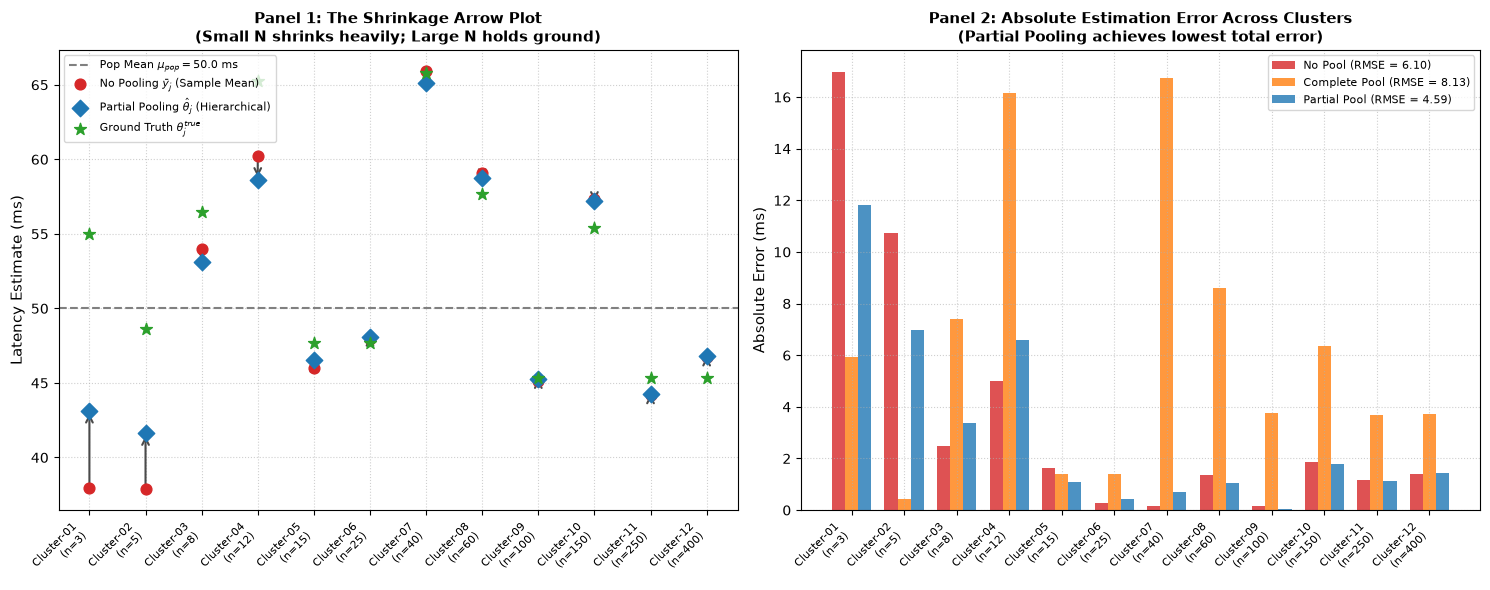

In [3]:
# ==============================================================================
# Part 4: The Iconic Shrinkage Visualization Dashboard (2-Panel Layout)
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# --- Panel 1: The Shrinkage Arrow Plot ---
x_indices = np.arange(J)

# Plot reference population line
ax1.axhline(mu_pop_true, color="gray", linestyle="--", linewidth=1.5,
            label=f"Pop Mean $\\mu_{{pop}} = {mu_pop_true:.1f}$ ms")

# Plot No-Pooling and Partial-Pooling points
ax1.scatter(x_indices, theta_no_pool, color="#d62728", s=60, zorder=4,
            label="No Pooling $\\bar{y}_j$ (Sample Mean)")
ax1.scatter(x_indices, theta_partial_pool, color="#1f77b4", s=70, marker="D",
            zorder=4, label="Partial Pooling $\\hat{\\theta}_j$ (Hierarchical)")
ax1.scatter(x_indices, theta_true, color="#2ca02c", s=80, marker="*",
            zorder=5, label="Ground Truth $\\theta_j^{true}$")

# Draw shrinkage arrows from No-Pool to Partial-Pool
for j in range(J):
    ax1.annotate("", xy=(x_indices[j], theta_partial_pool[j]),
                 xytext=(x_indices[j], theta_no_pool[j]),
                 arrowprops=dict(arrowstyle="->", color="#4a4a4a",
                                 lw=1.5, mutation_scale=12))

ax1.set_xticks(x_indices)
ax1.set_xticklabels([f"{group_names[j]}\n(n={n_samples[j]})" for j in range(J)],
                    rotation=45, ha="right", fontsize=8)
ax1.set_ylabel("Latency Estimate (ms)", fontsize=11)
ax1.set_title("Panel 1: The Shrinkage Arrow Plot\n"
              "(Small N shrinks heavily; Large N holds ground)",
              fontsize=11, fontweight="bold")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="upper left", fontsize=8)

# --- Panel 2: Estimation Error Comparison ---
err_no = np.abs(theta_no_pool - theta_true)
err_complete = np.abs(theta_complete_pool - theta_true)
err_partial = np.abs(theta_partial_pool - theta_true)

width = 0.25
ax2.bar(x_indices - width, err_no, width=width, color="#d62728", alpha=0.8,
        label=f"No Pool (RMSE = {rmse_no_pool:.2f})")
ax2.bar(x_indices, err_complete, width=width, color="#ff7f0e", alpha=0.8,
        label=f"Complete Pool (RMSE = {rmse_complete_pool:.2f})")
ax2.bar(x_indices + width, err_partial, width=width, color="#1f77b4", alpha=0.8,
        label=f"Partial Pool (RMSE = {rmse_partial_pool:.2f})")

ax2.set_xticks(x_indices)
ax2.set_xticklabels([f"{group_names[j]}\n(n={n_samples[j]})" for j in range(J)],
                    rotation=45, ha="right", fontsize=8)
ax2.set_ylabel("Absolute Error (ms)", fontsize=11)
ax2.set_title("Panel 2: Absolute Estimation Error Across Clusters\n"
              "(Partial Pooling achieves lowest total error)",
              fontsize=11, fontweight="bold")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()


---

## Part 5: 3-Tier Scaffolding Exercises

Practice the mathematical principles of hierarchical shrinkage and
parameterization
across three graduated challenge tiers:
* 🟢 **Tier 1 (Warmup / Mental Math)**: Hand-calculating the shrinkage weight
  $w_j$ and posterior mean for small vs. large sample groups.
* 🟡 **Tier 2 (Applied Engineering)**: Empirical Bayes Beta-Binomial hierarchical
  pooling across 10 test suites.
* 🔴 **Tier 3 (Production Challenge)**: Full Hierarchical MCMC sampling
  exposing Neal's Funnel and implementing the non-centered reparameterization.


---

### 🟢 Tier 1 (Mental Math & Hand Calculation): Shrinkage Weight Tug-of-War
> **Scenario**: An edge platform monitors latency across regional clusters.
> - Within-cluster observation noise is $\sigma = 16.0$ ms ($\sigma^2 = 256$).
> - Baseline between-cluster standard deviation is $\tau_{\text{pop}} = 8.0$ ms
> ($\tau_{\text{pop}}^2 = 64$).
> - Global population mean latency is $\mu_{\text{pop}} = 45.0$ ms.
>
> Two clusters both report an identical elevated sample mean latency of $\bar{y}
> = 68.0$ ms:
> - **Cluster A** (Canary): $n_A = 4$ observations.
> - **Cluster B** (Primary): $n_B = 250$ observations.
>
> **Your Task**:
> 1. Compute the prior effective sample size constant $\kappa = \sigma^2 /
> \tau_{\text{pop}}^2$.
> 2. Compute the shrinkage weights $w_A$ and $w_B$.
> 3. Calculate the posterior shrinkage estimates $\hat{\theta}_A$ and
> $\hat{\theta}_B$.
> 4. State how much each cluster shrunk toward $\mu_{\text{pop}}$.


In [4]:
# ============================================================
# 🟢 Tier 1: Your Turn — Attempt the Problem Here
# ============================================================
sigma_obs = 16.0
tau_pop = 8.0
mu_pop = 45.0

n_A = 4
y_bar_A = 68.0

n_B = 250
y_bar_B = 68.0

# 1. Compute prior effective sample size constant kappa:
# kappa = ...

# 2. Compute shrinkage weights w_A and w_B:
# w_A = ...
# w_B = ...

# 3. Compute posterior shrinkage estimates theta_hat_A and theta_hat_B:
# theta_hat_A = ...
# theta_hat_B = ...


<details>
<summary><b>🔍 Click here to view the solution & derivation</b></summary>

**Step-by-Step Derivation**:
1. **Prior effective sample size $\kappa$**:
$$\kappa = \frac{\sigma^2}{\tau_{\text{pop}}^2} = \frac{16.0^2}{8.0^2} =
\frac{256}{64} = \mathbf{4.0}$$
2. **Shrinkage Weights**:
$$w_A = \frac{n_A}{n_A + \kappa} = \frac{4}{4 + 4} = \frac{4}{8} =
\mathbf{0.500}$$
$$w_B = \frac{n_B}{n_B + \kappa} = \frac{250}{250 + 4} = \frac{250}{254} \approx
\mathbf{0.9843}$$
3. **Posterior Shrinkage Estimates**:
$$\hat{\theta}_A = (0.500 \times 68.0) + (1 - 0.500) \times 45.0 = 34.0 + 22.5 =
\mathbf{56.5\text{ ms}}$$
$$\hat{\theta}_B = (0.9843 \times 68.0) + (1 - 0.9843) \times 45.0 = 66.93 +
0.71 = \mathbf{67.64\text{ ms}}$$
4. **Shrinkage Amount**:
   - Cluster A shrunk by **$11.5$ ms** ($50.0\%$ toward population mean).
   - Cluster B shrunk by **$0.36$ ms** ($1.57\%$ toward population mean).

</details>


---

### 🟡 Tier 2 (Guided Calculation): Empirical Bayes Beta-Binomial Test Suites
> **Scenario**: A CI infrastructure tracks flaky failures across $J = 10$ test
> suites.
> Each suite has $n_j$ runs and $k_j$ observed flaky failures:
> - `n_runs = [5, 8, 12, 20, 35, 50, 80, 120, 200, 500]`
> - `failures = [0, 1, 0, 2, 1, 3, 2, 5, 8, 20]`
>
> **Your Task**:
> 1. Compute the raw sample flake rate for each suite: $\bar{p}_j = k_j / n_j$.
> 2. Estimate the population prior hyperparameters $(\alpha_0, \beta_0)$ using
>    Method-of-Moments on the suite sample proportions:
> $$\bar{p} = \frac{1}{J}\sum_{j=1}^J \bar{p}_j, \quad v =
> \frac{1}{J-1}\sum_{j=1}^J (\bar{p}_j - \bar{p})^2$$
> $$\alpha_0 = \bar{p}\left(\frac{\bar{p}(1-\bar{p})}{v} - 1\right), \quad
> \beta_0 = (1-\bar{p})\left(\frac{\bar{p}(1-\bar{p})}{v} - 1\right)$$
> 3. Compute the Empirical Bayes posterior mean for each suite:
>    $$\hat{p}_j = \frac{k_j + \alpha_0}{n_j + \alpha_0 + \beta_0}$$
> 4. Compare Suite 1 ($0/5$) to Suite 10 ($20/500$). Why is Suite 1's estimate
> not $0\%$?


In [5]:
# ============================================================
# 🟡 Tier 2: Your Turn — Attempt the Problem Here
# ============================================================
n_runs = np.array([5, 8, 12, 20, 35, 50, 80, 120, 200, 500])
failures = np.array([0, 1, 0, 2, 1, 3, 2, 5, 8, 20])

# 1. Compute raw proportions:
# p_raw = ...

# 2. Estimate population prior (alpha_0, beta_0) via Method-of-Moments:
# p_bar = ...
# v_bar = ...
# factor = ...
# alpha_0 = ...
# beta_0 = ...

# 3. Compute Empirical Bayes posterior mean:
# p_eb = ...


<details>
<summary><b>🔍 Click here to view the solution & analysis</b></summary>

**Step-by-Step Derivation**:
1. Raw sample proportions:
`p_raw = [0.000, 0.125, 0.000, 0.100, 0.029, 0.060, 0.025, 0.042, 0.040, 0.040]`
2. Mean and sample variance of proportions:
   - $\bar{p} \approx 0.0461$ ($4.61\%$ average flake rate across suites).
   - $v = \operatorname{Var}(\bar{p}_j) \approx 0.00185$.
- Common factor: $\left(\frac{\bar{p}(1-\bar{p})}{v} - 1\right) \approx
\frac{0.0461 \times 0.9539}{0.00185} - 1 \approx 22.78$.
   - $\alpha_0 = 0.0461 \times 22.78 \approx \mathbf{1.05}$.
   - $\beta_0 = (1 - 0.0461) \times 22.78 \approx \mathbf{21.73}$.
   - Total prior pseudo-runs: $\alpha_0 + \beta_0 \approx 22.78$ runs.
3. Empirical Bayes Posterior Means:
   - **Suite 1 ($0$ failures in $5$ runs)**:
$$\hat{p}_1 = \frac{0 + 1.05}{5 + 1.05 + 21.73} = \frac{1.05}{27.78} \approx
\mathbf{3.78\%}$$
   - **Suite 3 ($0$ failures in $12$ runs)**:
$$\hat{p}_3 = \frac{0 + 1.05}{12 + 22.78} = \frac{1.05}{34.78} \approx
\mathbf{3.02\%}$$
   - **Suite 10 ($20$ failures in $500$ runs)**:
$$\hat{p}_{10} = \frac{20 + 1.05}{500 + 22.78} = \frac{21.05}{522.78} \approx
\mathbf{4.03\%}$$
4. **Engineering Insight**: Suite 1's raw MLE of $0.0\%$ was a mirage of small
   sample size. Empirical Bayes correctly shrinks Suite 1 to $3.78\%$,
preventing the system from falsely promoting a flaky suite based on 5 lucky
passes.

</details>


---

### 🔴 Tier 3 (Production Challenge): Neal's Funnel & Non-Centered MCMC
> **Scenario**: When sampling hierarchical models using MCMC or HMC,
> parameterizing
> group parameters directly as $\theta_j \sim \mathcal{N}(\mu, \tau^2)$ creates
> a
> severe pathological geometry known as **Neal's Funnel**.
> As $\tau \to 0$, the conditional prior variance vanishes, forming a razor-thin
> crevasse in $(\log \tau, \theta)$ space where samplers get stuck.
>
> In the **Non-Centered Parameterization**, we transform:
> $$z_j \sim \mathcal{N}(0, 1) \quad \text{i.i.d.}, \quad \theta_j = \mu + \tau
> \cdot z_j$$
>
> **Your Task**:
> 1. Run a 3,000-step Metropolis-Hastings sampler for both the Centered and
> Non-Centered formulations of a hierarchical group parameter $\theta_1$ and
> $\log \tau$.
> 2. Plot the resulting MCMC sample trajectories in $(\log \tau, \theta_1)$
> space.
> 3. Observe why Centered MCMC freezes near the mouth of the funnel, while
>    Non-Centered MCMC seamlessly explores the narrow neck.


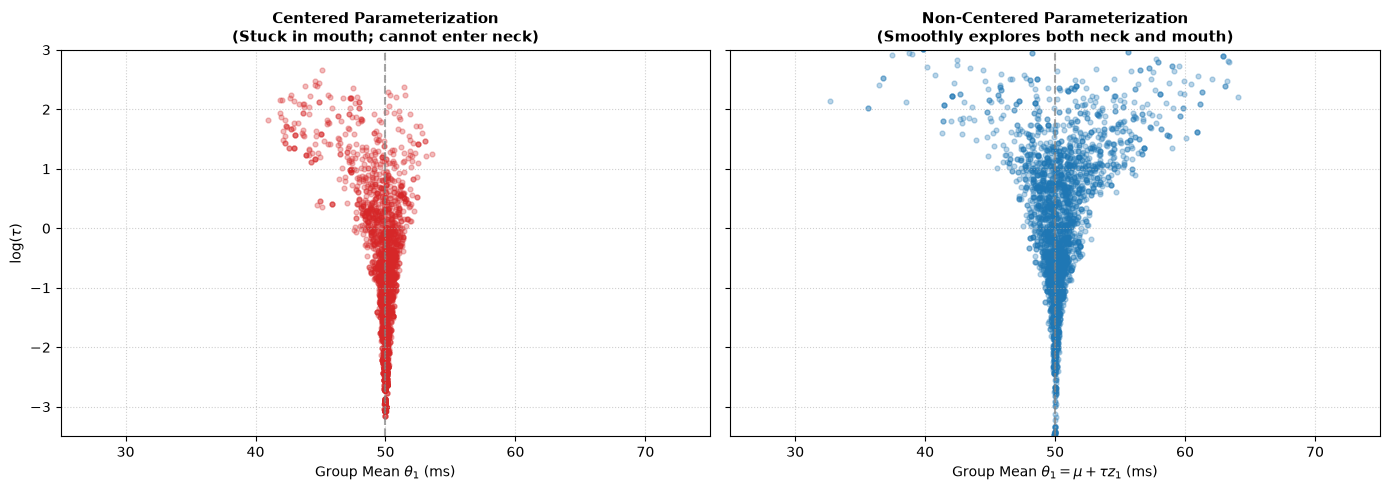

In [6]:
# ==============================================================================
# 🔴 Tier 3: Hierarchical MCMC — Centered vs Non-Centered Sampler & Funnel Plot
# ==============================================================================
np.random.seed(42)
n_iter = 3000

# True parameters for observation
mu_ground = 50.0
y_obs = 54.0   # Observed sample mean for group 1
sigma_obs = 10.0

# 1. Centered Sampler: state is (log_tau, theta)
trace_centered_lt = np.zeros(n_iter)
trace_centered_th = np.zeros(n_iter)

cur_lt = 1.0
cur_th = 50.0

def log_post_centered(lt, th):
    tau = np.exp(lt)
    lp_tau = -0.5 * (lt / 1.5)**2
    lp_th = -0.5 * ((th - mu_ground) / tau)**2 - lt
    ll = -0.5 * ((y_obs - th) / sigma_obs)**2
    return lp_tau + lp_th + ll

for i in range(n_iter):
    prop_lt = cur_lt + np.random.normal(0, 0.25)
    prop_th = cur_th + np.random.normal(0, 0.6)
    diff = (log_post_centered(prop_lt, prop_th) -
            log_post_centered(cur_lt, cur_th))
    if np.log(np.random.uniform()) < diff:
        cur_lt, cur_th = prop_lt, prop_th
    trace_centered_lt[i] = cur_lt
    trace_centered_th[i] = cur_th

# 2. Non-Centered Sampler: state is (log_tau, z)
trace_noncentered_lt = np.zeros(n_iter)
trace_noncentered_th = np.zeros(n_iter)

cur_lt = 1.0
cur_z = 0.0

def log_post_noncentered(lt, z):
    tau = np.exp(lt)
    th = mu_ground + tau * z
    lp_tau = -0.5 * (lt / 1.5)**2
    lp_z = -0.5 * (z**2)
    ll = -0.5 * ((y_obs - th) / sigma_obs)**2
    return lp_tau + lp_z + ll

for i in range(n_iter):
    prop_lt = cur_lt + np.random.normal(0, 0.25)
    prop_z = cur_z + np.random.normal(0, 0.6)
    diff = (log_post_noncentered(prop_lt, prop_z) -
            log_post_noncentered(cur_lt, cur_z))
    if np.log(np.random.uniform()) < diff:
        cur_lt, cur_z = prop_lt, prop_z
    trace_noncentered_lt[i] = cur_lt
    trace_noncentered_th[i] = mu_ground + np.exp(cur_lt) * cur_z

# Visualization: Exposing Neal's Funnel
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

ax1.scatter(trace_centered_th, trace_centered_lt, alpha=0.3,
            color="#d62728", s=12)
ax1.axvline(mu_ground, color="gray", linestyle="--", alpha=0.7)
ax1.set_title("Centered Parameterization\n"
              "(Stuck in mouth; cannot enter neck)",
              fontsize=11, fontweight="bold")
ax1.set_xlabel("Group Mean $\\theta_1$ (ms)", fontsize=10)
ax1.set_ylabel("$\\log(\\tau)$", fontsize=10)
ax1.set_xlim(mu_ground - 25, mu_ground + 25)
ax1.set_ylim(-3.5, 3.0)
ax1.grid(True, linestyle=":", alpha=0.6)

ax2.scatter(trace_noncentered_th, trace_noncentered_lt, alpha=0.3,
            color="#1f77b4", s=12)
ax2.axvline(mu_ground, color="gray", linestyle="--", alpha=0.7)
ax2.set_title("Non-Centered Parameterization\n"
              "(Smoothly explores both neck and mouth)",
              fontsize=11, fontweight="bold")
ax2.set_xlabel("Group Mean $\\theta_1 = \\mu + \\tau z_1$ (ms)", fontsize=10)
ax2.set_xlim(mu_ground - 25, mu_ground + 25)
ax2.set_ylim(-3.5, 3.0)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


<details>
<summary><b>🔍 Click here to view the mathematical proof & geometric
explanation</b></summary>

**Mathematical Proof & Geometric Analysis**:
1. **The Gradient Singularity in Centered Parameterization**:
In the centered model, the gradient of the log-prior with respect to $\theta_j$
is:
$$\frac{\partial}{\partial \theta_j} \log p(\theta_j \mid \mu, \tau) =
-\frac{\theta_j - \mu}{\tau^2}$$
As $\tau \to 0$ (entering the neck of the funnel), the curvature
$\frac{1}{\tau^2} \to \infty$.
To avoid rejecting proposals, a random-walk proposal step size or HMC leapfrog
integrator must scale as $\mathcal{O}(\tau)$. Any step size $\epsilon$
calibrated
for the mouth ($\tau \approx 2$) will wildly overshoot the neck, yielding $0\%$
   acceptance.
2. **The Non-Centered Decoupling**:
   In the non-centered model:
   $$\frac{\partial}{\partial z_j} \log p(z_j) = -z_j$$
   The curvature is **constant and equal to $1.0$ everywhere**, completely
   independent of $\tau$!
3. **Rule of Thumb for Production Hierarchical Modeling**:
   - When data per group is **sparse ($n_j$ small)**: Use the **Non-Centered**
parameterization (prior geometry dominates, non-centered avoids the funnel).
   - When data per group is **dense ($n_j$ large)**: Use the **Centered**
     parameterization (likelihood dominates and pins $\theta_j$, rendering
     centered geometry well-conditioned).

</details>


---

## 🎓 Conclusion: The Hierarchical Bayes Advantage

Hierarchical models represent the pinnacle of Bayesian synthesis:
* **The Classical Failure**: No Pooling overfits small sample clusters; Complete
  Pooling ignores genuine systemic variance.
* **The Bayesian Solution**: Partial Pooling dynamically learns the population
  distribution from the collective data, allowing small groups to borrow
  statistical strength from large groups.
* **Stein's Paradox**: For $J \ge 3$ groups, shrinkage strictly dominates
  unpooled sample averages under total squared error loss.
* **Computational Mastery**: Non-centered parameterization eliminates Neal's
Funnel,
  unlocking robust MCMC and HMC sampling across hundreds of production clusters.

---
## 🧭 Course Navigation

* 🏠 **[Course Home & Master Syllabus](00_START_HERE.ipynb)**
* ⬅️ **Previous**: **[Ch 12: Bayesian Regression, Counts & GLMs](12_bayesian_regression_and_glms.ipynb)** *(Part III: Applied Modeling, Regression, Hierarchy & Model Comparison)*
* ➡️ **Next**: **[Ch 14: Marginal Likelihood & Occam's Razor](14_marginal_likelihood_and_model_comparison.ipynb)** *(Part III: Applied Modeling, Regression, Hierarchy & Model Comparison)*
* 🔄 **Companion Tracks for Chapter 13**: [📖 Conceptual](../conceptual/13_hierarchical_models_and_partial_pooling.ipynb) | [🤖 AI-Native](../ai/13_hierarchical_models_and_partial_pooling.ipynb) | [🐍 Python](../python/13_hierarchical_models_and_partial_pooling.ipynb) | [🔵 R](../r/13_hierarchical_models_and_partial_pooling.ipynb)
